# Backtracking y el recorrido del caballo

**Inteligencia Artificial · IS784 · Taller de laboratorio**

Un caballo debe visitar cada casilla del tablero exactamente una vez. Puede terminar en cualquier casilla en un **recorrido abierto**. Para un **recorrido cerrado**, además debe poder saltar de la última casilla a la inicial. En este taller, «abierto» significa que no se exige el salto de regreso.

**Objetivos**

- Representar una solución parcial y formular el caso base de una búsqueda recursiva.
- Explicar qué debe restaurarse al abandonar una rama.
- Implementar, probar y animar un solucionador propio.
- Medir el efecto del orden de exploración sobre el trabajo de la búsqueda.

Las coordenadas son pares `(fila, columna)` numerados desde cero. La fila crece hacia abajo. Un salto legal cumple `(|Δfila|, |Δcolumna|) = (1, 2)` o `(2, 1)`. Por ejemplo, desde `(0, 0)` se puede ir a `(1, 2)` o a `(2, 1)`.

Ejecute las celdas en orden con Python 3. La animación ya está incluida en el cuaderno. Para regenerarla se necesitan Pillow y Matplotlib. Si faltan en su entorno de Jupyter, ejecute `%pip install pillow matplotlib` en una celda y vuelva a ejecutar el cuaderno.

---
### SOLUCIÓN · presentación

**Integrantes:** Santiago Valencia León (C.C. 1032797866) y Juan Manuel Galvis (C.C. 1004520611).

**Cómo leer este cuaderno.** El enunciado está completo y sin cambios. Nuestra solución está debajo de cada parte, siempre después de una celda que dice **SOLUCIÓN**, y llega hasta donde empieza la siguiente parte del enunciado. Las celdas de código del enunciado también se conservan: la plantilla del Reto 1 y 2 sigue ahí, y nuestra versión de `saltos_legales` y `resolver` la reemplaza en la celda siguiente.

**Reglas que seguimos.**

- **El solucionador es nuestro.** No usamos bibliotecas de búsqueda. Fuera de la biblioteca estándar solo usamos Pillow y Matplotlib (las pide el enunciado para la animación) y `pandas` para mostrar tablas.
- **Nombres.** Los nombres que fija el enunciado quedan en español (`saltos_legales`, `resolver`, `camino`, `visitadas`, `traza`, los estados `"éxito"`, `"fracaso"`, `"límite"`). El código auxiliar que escribimos nosotros va en inglés (`advance`, `retreat`, `replay`, `oracle`). Las explicaciones van en español.
- **Caso asignado.** El docente no nos asignó un caso en clase. Para no escoger uno que nos favoreciera, lo sacamos de nuestras cédulas antes de ejecutar nada: tablero 6x6 (el 5x5 ya está en la tabla), inicio `(6 mod 6, 1 mod 6) = (0, 1)` con los últimos dígitos de cada cédula, y rotación `(6 + 1) mod 8 = 7`. Está en una sola celda (`CASO`, abajo); si el docente asigna otro, se cambia ahí y se vuelve a ejecutar.
- **Verificación.** Todo resultado importante se compara con algo independiente: la traza que grabó el docente (Reto 2) y un segundo buscador escrito de otra forma, el oráculo (Reto 3).

In [1]:
import platform
import time
from inspect import getsource

import matplotlib
import pandas as pd
import PIL

print(f"Python {platform.python_version()} · Pillow {PIL.__version__} · "
      f"Matplotlib {matplotlib.__version__} · pandas {pd.__version__}")

Python 3.14.8 · Pillow 13.0.0 · Matplotlib 3.11.2 · pandas 3.1.1


In [2]:
# Our case (the teacher did not assign one); see the rules above.
CASO = {"n": 6, "inicio": (0, 1), "rotacion": 7}
PRESUPUESTO = 50_000


def rotate(orden, k):
    return tuple(orden[k:]) + tuple(orden[:k])


print(CASO, "presupuesto:", PRESUPUESTO)

{'n': 6, 'inicio': (0, 1), 'rotacion': 7} presupuesto: 50000


## 1. Elegir, explorar y deshacer

Cada nodo del árbol de búsqueda representa un **camino parcial**. Sus hijos corresponden a saltos legales que aún no aparecen en ese camino. Una misma posición puede aparecer en diferentes ramas porque las demás casillas visitadas pueden ser distintas.

Conserve dos estructuras: `camino`, que guarda el orden de los saltos, y `visitadas`, que permite comprobar la pertenencia con un conjunto. Justo antes y después de explorar una rama fallida debe mantenerse el invariante `visitadas == set(camino)`. Al volver de esa rama se debe haber recuperado exactamente el camino anterior, en el mismo orden.

```text
BUSCAR
    si el camino ocupa todas las casillas:
        devolver si cumple la condición del recorrido

    para cada destino legal y libre desde la última casilla:
        agregar el destino al camino y marcarlo como visitado
        si BUSCAR devuelve éxito:
            devolver éxito
        quitar el destino del camino y desmarcarlo

    devolver fracaso
```

Una llamada puede fracasar porque se quedó sin destinos libres o porque agotó todos sus descendientes. Cuando eso ocurre, su llamador deshace el salto que lo llevó allí y prueba la siguiente alternativa. Si una rama tiene éxito, las llamadas retornan conservando el camino completo.

Con `N` casillas, la pila recursiva puede alcanzar profundidad `N`. Un límite superior grueso para el árbol es `O(8^N)`; las restricciones reducen la cantidad de ramas efectivas. El camino, el conjunto y la pila usan `O(N)` de espacio. Guardar todos los eventos de animación añade espacio lineal en el número de eventos registrados.

---
### SOLUCIÓN · sección 1

**Qué es un nodo.** Un nodo no es una casilla, es un camino parcial: la lista de casillas en el orden en que el caballo las visitó. Por eso la misma casilla puede aparecer en muchas ramas: llegar a `(2, 2)` después de 10 casillas no es lo mismo que llegar después de 20, porque las casillas libres son otras.

**Por qué dos estructuras.** `camino` guarda el orden, que es la respuesta y nos dice dónde está el caballo (`camino[-1]`). `visitadas` es un conjunto para preguntar "¿ya pasé por aquí?" en tiempo constante; con la lista habría que recorrerla entera en cada salto.

**Qué se restaura al abandonar una rama.** Exactamente lo que se cambió al entrar: se quita la última casilla de `camino` y esa misma casilla de `visitadas`. Nada más. Si se olvida quitarla de `visitadas`, la casilla queda bloqueada para las demás ramas y la búsqueda se salta soluciones que existen (en la sección 4 mostramos ese error y la prueba que lo detecta). En nuestro código solo dos funciones tocan el estado, `advance` y `retreat`, y cada una escribe su evento en la traza. Así el invariante `visitadas == set(camino)` se cumple antes y después de cada rama.

**Costo.** La pila llega a profundidad `N = n²`, una llamada por casilla del camino. Cada nodo tiene a lo sumo 8 hijos, de ahí la cota gruesa `O(8^N)`; en la práctica hay muchos menos porque los bordes y las casillas visitadas cortan saltos (en 5x5 el árbol completo desde una esquina tiene 1 735 079 nodos, no 8^25). En memoria, `camino`, `visitadas` y la pila son `O(N)`; la traza crece con el número de eventos, que es lo que más ocupa en búsquedas largas.

## 2. Observe un retroceso

La traza se grabó en un tablero **5×5**, desde **(0, 0)**, con un orden fijo de movimientos escogido para que se vean varios retrocesos en poco tiempo. El verde señala un avance. En naranja, el caballo queda en la casilla a la que volvió y el aspa marca la casilla que acaba de liberar. Los números muestran la posición de cada casilla en el camino actual. La animación se repite automáticamente.

Antes de verla, prediga qué ocurre con el último número del tablero cuando el caballo retrocede. Después, use el visor de fotogramas para comprobar su predicción.

In [3]:
TRAZA_DEMO = [('inicio', 0, 0), ('avance', 1, 2), ('avance', 0, 4), ('avance', 2, 3), ('avance', 4, 4), ('avance', 3, 2), ('avance', 2, 4), ('avance', 4, 3), ('avance', 3, 1), ('avance', 1, 0), ('avance', 0, 2), ('avance', 1, 4), ('avance', 3, 3), ('avance', 4, 1), ('avance', 2, 0), ('avance', 0, 1), ('avance', 1, 3), ('avance', 3, 4), ('avance', 4, 2), ('avance', 3, 0), ('avance', 2, 2), ('avance', 0, 3), ('avance', 1, 1), ('retroceso', 1, 1), ('retroceso', 0, 3), ('retroceso', 2, 2), ('avance', 1, 1), ('avance', 0, 3), ('avance', 2, 2), ('retroceso', 2, 2), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 2, 2), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('retroceso', 4, 0), ('retroceso', 2, 1), ('retroceso', 4, 2), ('avance', 1, 1), ('avance', 0, 3), ('retroceso', 0, 3), ('retroceso', 1, 1), ('retroceso', 3, 0), ('avance', 0, 3), ('avance', 1, 1), ('avance', 3, 0), ('avance', 4, 2), ('avance', 2, 1), ('avance', 4, 0), ('éxito', 4, 0)]

In [4]:
from io import BytesIO

from IPython.display import Image as NotebookImage, display
from matplotlib import get_data_path
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

FONT_DIR = Path(get_data_path()) / "fonts" / "ttf"
FONT = FONT_DIR / "DejaVuSans.ttf"
TEXT_FONT = ImageFont.truetype(str(FONT), 17)
TITLE_FONT = ImageFont.truetype(str(FONT), 20)
HORSE_FONT = ImageFont.truetype(str(FONT), 31)

LABELS = {
    "inicio": "Inicio", "avance": "Avance", "retroceso": "Retroceso",
    "éxito": "Recorrido completo", "fracaso": "Búsqueda agotada",
    "límite": "Presupuesto agotado",
}


def dibujar_fotograma(n, camino, evento, indice):
    """Dibuja el camino después de aplicar el evento."""
    paso = min(60, 380 // n)
    margen_x, margen_y = 40, 66
    ancho = n * paso
    fondo = Image.new("RGB", (max(415, ancho + 66), ancho + 117), "#f8fafc")
    draw = ImageDraw.Draw(fondo)
    tipo, fila, columna = evento
    color = "#b45309" if tipo == "retroceso" else "#047857"
    draw.text((16, 11), f"{indice:02d} · {LABELS[tipo]}", font=TITLE_FONT,
              fill=color if tipo in {"avance", "retroceso", "éxito"} else "#0f172a")

    def esquina(f, c):
        return margen_x + c * paso, margen_y + f * paso

    for f in range(n):
        draw.text((19, margen_y + f * paso + paso / 2), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        draw.text((margen_x + f * paso + paso / 2, 52), str(f), font=TEXT_FONT,
                  anchor="mm", fill="#334155")
        for c in range(n):
            x, y = esquina(f, c)
            base = "#e2e8f0" if (f + c) % 2 == 0 else "#b8cadb"
            draw.rectangle((x, y, x + paso - 1, y + paso - 1), fill=base)

    for numero, (f, c) in enumerate(camino, start=1):
        x, y = esquina(f, c)
        actual = numero == len(camino)
        draw.rectangle((x + 2, y + 2, x + paso - 3, y + paso - 3),
                       fill=color if actual else "#d1fae5")
        if actual:
            draw.text((x + paso / 2, y + paso * 0.59), "♞", font=HORSE_FONT,
                      anchor="mm", fill="#ffffff")
            draw.text((x + 5, y + 2), str(numero), font=TEXT_FONT, fill="#ffffff")
        else:
            draw.text((x + paso / 2, y + paso / 2), str(numero), font=TEXT_FONT,
                      anchor="mm", fill="#064e3b")

    if tipo == "retroceso":
        x, y = esquina(fila, columna)
        draw.rectangle((x + 3, y + 3, x + paso - 4, y + paso - 4),
                       outline=color, width=3)
        draw.text((x + paso / 2, y + paso / 2), "×", font=HORSE_FONT,
                  anchor="mm", fill=color)

    draw.text((16, margen_y + ancho + 14),
              f"Visitadas {len(camino)}/{n*n} · Evento en ({fila}, {columna})",
              font=TEXT_FONT, fill="#0f172a")
    return fondo


def fotogramas(n, traza):
    """Reproduce eventos ya registrados; la búsqueda ocurre por separado."""
    camino = []
    for indice, evento in enumerate(traza):
        tipo, fila, columna = evento
        casilla = (fila, columna)
        if tipo in {"inicio", "avance"}:
            camino.append(casilla)
        elif tipo == "retroceso":
            if len(camino) < 2 or camino[-1] != casilla:
                raise ValueError(f"Retroceso incoherente en el evento {indice}")
            camino.pop()
        yield dibujar_fotograma(n, camino, evento, indice)


def gif_traza(n, traza):
    cuadros = list(fotogramas(n, traza))
    duraciones = [650 if evento[0] == "retroceso" else 280 for evento in traza]
    duraciones[0] = 950
    duraciones[-1] = 2200
    archivo = BytesIO()
    cuadros[0].save(archivo, format="GIF", save_all=True, append_images=cuadros[1:],
                    duration=duraciones, loop=0)
    return archivo.getvalue()

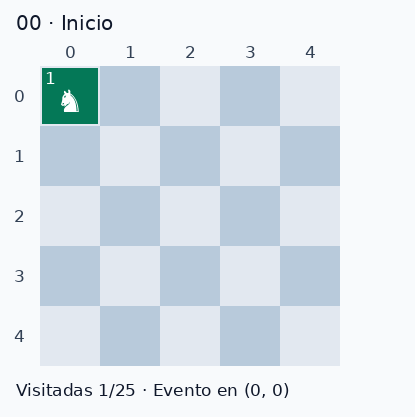

In [5]:
gif_demo = gif_traza(5, TRAZA_DEMO)
salida_gif = gif_demo, "image/gif"
display(NotebookImage(data=gif_demo, format="gif"))

### Laboratorio de observación

1. Seleccione el primer fotograma de retroceso. Registre las coordenadas de la casilla liberada y de la casilla a la que vuelve el caballo. ¿Cuántas casillas están visitadas antes y después?
2. Dibuje la pila de llamadas para los últimos tres niveles justo antes y después de ese retroceso. Localice el marco que elige el siguiente destino.
3. Encuentre en la traza una casilla que se libera y más tarde vuelve a aparecer como destino. Explique por qué esa segunda visita es válida.

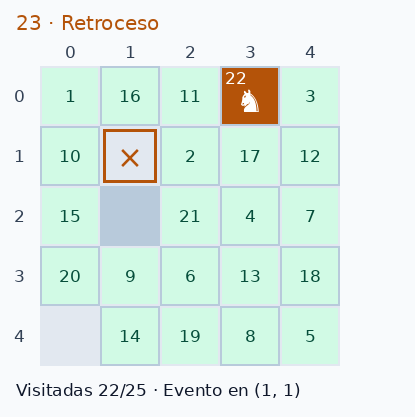

In [6]:
from itertools import islice


def ver_fotograma(n, traza, indice):
    if not 0 <= indice < len(traza):
        raise IndexError(f"Use un índice entre 0 y {len(traza) - 1}")
    cuadro = next(islice(fotogramas(n, traza), indice, None))
    archivo = BytesIO()
    cuadro.save(archivo, format="PNG")
    return archivo.getvalue()


indice = next(i for i, evento in enumerate(TRAZA_DEMO) if evento[0] == "retroceso")
# Cambie indice por indice - 1 o indice + 1 para comparar.
imagen_paso = ver_fotograma(5, TRAZA_DEMO, indice)
salida_paso = imagen_paso, "image/png"
display(NotebookImage(data=imagen_paso, format="png"))

---
### SOLUCIÓN · sección 2 (laboratorio de observación)

**Predicción antes de ver la animación.** Al retroceder, el número más alto del tablero desaparece: esa casilla se libera y vuelve a verse vacía. El caballo queda en la casilla que tenía el número anterior, que pasa a ser el último. El contador de visitadas baja en uno.

Para responder con datos reconstruimos el camino después de cada evento de la traza. `replay` hace lo mismo que `fotogramas`, pero sin dibujar.

Primer retroceso: evento 23, ('retroceso', 1, 1)
Casilla liberada: (1, 1); el caballo vuelve a (0, 3)
Visitadas antes: 23; después: 22
Eventos siguientes: [('retroceso', 0, 3), ('retroceso', 2, 2), ('avance', 1, 1)]


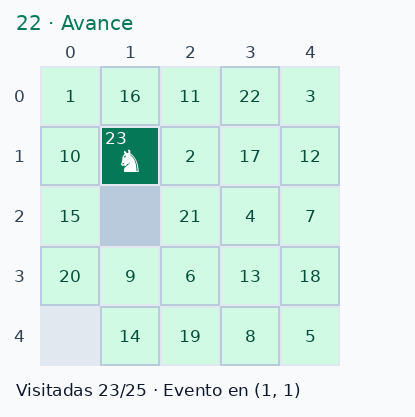

In [7]:
def replay(traza):
    """Path after each event of a trace."""
    path, paths = [], []
    for tipo, fila, columna in traza:
        if tipo in ("inicio", "avance"):
            path.append((fila, columna))
        elif tipo == "retroceso":
            assert path[-1] == (fila, columna), "incoherent retroceso"
            path.pop()
        paths.append(list(path))
    return paths


caminos_demo = replay(TRAZA_DEMO)
i = next(k for k, e in enumerate(TRAZA_DEMO) if e[0] == "retroceso")
print(f"Primer retroceso: evento {i}, {TRAZA_DEMO[i]}")
print(f"Casilla liberada: {TRAZA_DEMO[i][1:]}; el caballo vuelve a {caminos_demo[i][-1]}")
print(f"Visitadas antes: {len(caminos_demo[i - 1])}; después: {len(caminos_demo[i])}")
print("Eventos siguientes:", TRAZA_DEMO[i + 1:i + 4])
display(NotebookImage(data=ver_fotograma(5, TRAZA_DEMO, i - 1), format="png"))

Arriba está el fotograma anterior al retroceso (evento 22) y, en la celda del enunciado, el del retroceso (evento 23). La predicción se cumplió: el 23 desaparece de `(1, 1)` y el caballo queda en `(0, 3)`, con el 22.

**1. Primer retroceso.** Es el evento 23. Se libera `(1, 1)` y el caballo vuelve a `(0, 3)`. Antes había 23 casillas visitadas y después 22. El caballo había llegado a `(1, 1)` sin ningún salto libre, así que esa llamada fracasó.

**2. La pila de llamadas, últimos tres niveles.** Cada marco es una llamada a `BUSCAR` cuyo camino termina en esa casilla.

```text
Justo antes (evento 22)                 Justo después (evento 23)

nivel 23  BUSCAR ... (1, 1)  <- tope
          sin destinos libres: fracasa
nivel 22  BUSCAR ... (0, 3)             nivel 22  BUSCAR ... (0, 3)  <- tope
          probando (1, 1)                         elige el siguiente destino
nivel 21  BUSCAR ... (2, 2)             nivel 21  BUSCAR ... (2, 2)
          probando (0, 3)                         probando (0, 3)
                                        nivel 20  BUSCAR ... (3, 0)
                                                  probando (2, 2)
```

El marco que elige el siguiente destino es el de `(0, 3)`: es el que hizo el avance a `(1, 1)`, así que es él quien lo deshace y sigue con su ciclo. No le quedan alternativas, y por eso el evento 24 es otro retroceso, `(0, 3)`. Lo mismo le pasa a `(2, 2)` en el evento 25. Recién el marco de `(3, 0)` tiene otra opción, y en el evento 26 avanza a `(1, 1)`.

**3. Una casilla que vuelve.** `(1, 1)` se libera en el evento 23 y vuelve a ser destino en el evento 26 (la celda de abajo la encuentra). La segunda visita es válida porque al retroceder se quitó de `camino` y de `visitadas`; para la búsqueda esa casilla está libre otra vez. Además el camino es otro: la primera vez se llegó desde `(0, 3)` con 22 casillas detrás; la segunda, desde `(3, 0)` con 20. Es otro nodo del árbol aunque la casilla sea la misma.

In [8]:
liberadas = {}
for k, (tipo, fila, columna) in enumerate(TRAZA_DEMO):
    if tipo == "retroceso":
        liberadas.setdefault((fila, columna), k)
    elif tipo == "avance" and (fila, columna) in liberadas:
        print(f"{(fila, columna)}: liberada en el evento {liberadas[(fila, columna)]}, "
              f"vuelve en el evento {k} desde {caminos_demo[k][-2]} "
              f"con {len(caminos_demo[k]) - 1} casillas antes")
        break

(1, 1): liberada en el evento 23, vuelve en el evento 26 desde (3, 0) con 20 casillas antes


## 3. Implemente su solucionador

### Reto 1 · Genere saltos legales

Complete `saltos_legales`. Use los ocho desplazamientos, compruebe los límites y descarte toda casilla de `visitadas`. Conserve el orden de entrada. Compruebe a mano los casos de una esquina, una casilla central y un tablero pequeño donde no cabe ningún salto.

### Reto 2 · Construya la búsqueda recursiva

Complete `resolver` para recorridos abiertos y pruebe primero con tableros de 1×1, 3×3 y 5×5. Use un conjunto para las visitadas y deje el registro de eventos bajo el control de las operaciones que modifican el camino. Elija una rama fallida de su propia ejecución y compruebe el invariante antes y después de explorarla.

**Contrato**

- `resolver` recibe `n` entero positivo, un inicio dentro del tablero, una permutación de `DESPLAZAMIENTOS`, y una estrategia `"fijo"` o `"warnsdorff"`. El presupuesto es un entero positivo.
- Devuelve `(estado, camino, traza, expansiones)`. Los estados son `"éxito"`, `"fracaso"` y `"límite"`. Devuelva una lista de coordenadas para el camino exitoso y `None` en los otros dos estados.
- Cuente una expansión cada vez que entra a procesar un camino parcial, incluida la raíz y los casos base. Si queda un destino por explorar y no hay presupuesto para procesarlo, devuelva límite antes de registrar ese avance. Una llamada ya contabilizada puede reconocer un caso base exitoso aunque consuma la última expansión.
- La traza empieza con `("inicio", fila, columna)`. Un avance identifica la casilla agregada. Un retroceso identifica la casilla retirada, incluso si la búsqueda está desenrollando la pila tras alcanzar el presupuesto. El último evento usa el estado de retorno y las coordenadas donde quedó el camino tras el desenrollado.
- Si se agota el presupuesto, propague ese estado hasta la raíz. Si se agota todo el árbol, devuelva fracaso. La raíz conserva la casilla inicial en ambos casos.
- Puede registrar una ejecución corta para el GIF y usar trazas largas solo para contar eventos o inspeccionar fotogramas puntuales.

In [9]:
DESPLAZAMIENTOS = (
    (-1, 2), (1, 2), (2, 1), (2, -1),
    (1, -2), (-1, -2), (-2, -1), (-2, 1),
)


def saltos_legales(n, posicion, visitadas, orden):
    """Devuelve las casillas libres alcanzables, en el orden recibido."""
    raise NotImplementedError("Reto 1")


def resolver(n, inicio, *, orden=DESPLAZAMIENTOS, estrategia="fijo",
             cerrado=False, presupuesto=50_000):
    """Devuelve estado, camino, traza y número de expansiones."""
    # Inicialice el camino y las visitadas.
    # Defina la función recursiva y ubique el caso base.
    # Registre los cambios de estado y pruebe las ramas candidatas.
    raise NotImplementedError("Retos 2 y 3")

---
### SOLUCIÓN · Retos 1 y 2

La celda del enunciado de arriba deja `saltos_legales` y `resolver` sin hacer. Esta celda las reemplaza con nuestra versión.

**Cómo funciona `resolver`.**

- `advance` y `retreat` son las únicas que cambian `camino` y `visitadas`, y cada una escribe su evento. Así la traza siempre coincide con lo que hizo la búsqueda.
- `search` suma una expansión apenas entra, incluida la raíz y los casos base. Luego mira si el camino ya cubre el tablero: en modo abierto eso es éxito; en modo cerrado además pide que el último salto pueda volver al inicio.
- Antes de cada avance mira el presupuesto. Si ya se gastó, devuelve `"límite"` sin registrar ese avance. Al volver de una llamada fallida o cortada siempre deshace el avance; por eso al cortar por presupuesto la traza muestra los retrocesos de todo el desenrollado hasta la raíz.
- El último evento lleva el estado y la casilla donde quedó el camino: la última del recorrido si hubo éxito, el inicio si no.
- Con `"warnsdorff"` solo cambia el orden de los candidatos (ver Reto 3); el retroceso es el mismo.

In [10]:
def saltos_legales(n, posicion, visitadas, orden):
    """Devuelve las casillas libres alcanzables, en el orden recibido."""
    fila, columna = posicion
    destinos = []
    for df, dc in orden:
        destino = (fila + df, columna + dc)
        if 0 <= destino[0] < n and 0 <= destino[1] < n and destino not in visitadas:
            destinos.append(destino)
    return destinos


def es_salto(a, b):
    # Same as the statement's helper (Reto 3 cell); resolver needs it before that cell runs.
    return sorted((abs(a[0] - b[0]), abs(a[1] - b[1]))) == [1, 2]


def resolver(n, inicio, *, orden=DESPLAZAMIENTOS, estrategia="fijo",
             cerrado=False, presupuesto=50_000):
    """Devuelve estado, camino, traza y número de expansiones."""
    if not (isinstance(n, int) and n > 0):
        raise ValueError("n must be a positive integer")
    if not (0 <= inicio[0] < n and 0 <= inicio[1] < n):
        raise ValueError("start square is outside the board")
    if sorted(orden) != sorted(DESPLAZAMIENTOS):
        raise ValueError("orden must be a permutation of DESPLAZAMIENTOS")
    if estrategia not in ("fijo", "warnsdorff"):
        raise ValueError("estrategia must be 'fijo' or 'warnsdorff'")
    if not (isinstance(presupuesto, int) and presupuesto > 0):
        raise ValueError("presupuesto must be a positive integer")

    camino = [inicio]
    visitadas = {inicio}
    traza = [("inicio", *inicio)]
    expansiones = 0

    def advance(square):
        camino.append(square)
        visitadas.add(square)
        traza.append(("avance", *square))

    def retreat():
        square = camino.pop()
        visitadas.discard(square)
        traza.append(("retroceso", *square))
        # O(1) guard for visitadas == set(camino); the full check is in the Reto 2 solution
        assert len(visitadas) == len(camino)

    def candidates():
        destinos = saltos_legales(n, camino[-1], visitadas, orden)
        if estrategia == "warnsdorff":
            # sorted() is stable, so ties keep the received order
            destinos.sort(key=lambda d: len(saltos_legales(n, d, visitadas | {d}, orden)))
        return destinos

    def search():
        nonlocal expansiones
        expansiones += 1
        if len(camino) == n * n:
            return "éxito" if not cerrado or es_salto(camino[-1], inicio) else "fracaso"
        for destino in candidates():
            if expansiones >= presupuesto:
                return "límite"
            advance(destino)
            estado = search()
            if estado == "éxito":
                return estado
            retreat()
            if estado == "límite":
                return estado
        return "fracaso"

    estado = search()
    # search refers to itself through its closure; breaking that cycle frees long traces right away
    del search
    traza.append((estado, *camino[-1]))
    return estado, (list(camino) if estado == "éxito" else None), traza, expansiones

**Reto 1 a mano.** Desde `(0, 0)` en 5x5, sumando cada desplazamiento en el orden de `DESPLAZAMIENTOS`:

| Desplazamiento | Destino | ¿Legal? |
|---|---|---|
| (-1, 2) | (-1, 2) | No, fila -1 |
| (1, 2) | (1, 2) | Sí |
| (2, 1) | (2, 1) | Sí |
| (2, -1) | (2, -1) | No, columna -1 |
| (1, -2) | (1, -2) | No |
| (-1, -2) | (-1, -2) | No |
| (-2, -1) | (-2, -1) | No |
| (-2, 1) | (-2, 1) | No |

Quedan `[(1, 2), (2, 1)]`, en ese orden. Desde el centro `(2, 2)` caben los ocho saltos, porque ninguno se sale de las filas y columnas 0 a 4. En 2x2 no cabe ningún salto: todos piden moverse dos casillas en alguna dirección. Si además `(1, 2)` está visitada, solo queda `(2, 1)`. La celda de abajo comprueba los cuatro casos.

In [11]:
casos_reto1 = [
    ("esquina 5x5", 5, (0, 0), {(0, 0)}),
    ("esquina con (1, 2) visitada", 5, (0, 0), {(0, 0), (1, 2)}),
    ("centro 5x5", 5, (2, 2), {(2, 2)}),
    ("tablero 2x2", 2, (0, 0), {(0, 0)}),
]
for nombre, n, pos, vis in casos_reto1:
    print(f"{nombre:28s} {saltos_legales(n, pos, vis, DESPLAZAMIENTOS)}")

esquina 5x5                  [(1, 2), (2, 1)]
esquina con (1, 2) visitada  [(2, 1)]
centro 5x5                   [(1, 4), (3, 4), (4, 3), (4, 1), (3, 0), (1, 0), (0, 1), (0, 3)]
tablero 2x2                  []


**Reto 2: primeras corridas.** En 1x1 el camino ya cubre el tablero en la raíz: éxito con una expansión. En 3x3 no hay recorrido (la casilla central no tiene saltos y las otras ocho forman un solo ciclo que nunca la toca), así que la búsqueda agota el árbol. En 5x5 desde `(0, 0)` hay recorrido.

In [12]:
filas = []
for n in (1, 3, 5):
    estado, camino, traza, expansiones = resolver(n, (0, 0))
    filas.append({"Tablero": f"{n}x{n}", "Estado": estado, "Expansiones": expansiones,
                  "Retrocesos": sum(e[0] == "retroceso" for e in traza),
                  "Casillas del camino": len(camino) if camino else None,
                  "Último evento": traza[-1]})
display(pd.DataFrame(filas))

,Tablero,Estado,Expansiones,Retrocesos,Casillas del camino,Último evento
0,1x1,éxito,1,0,1.0,"(éxito, 0, 0)"
1,3x3,fracaso,15,14,NaN,"(fracaso, 0, 0)"
2,5x5,éxito,41,16,25.0,"(éxito, 4, 0)"


**Comparación con la traza del docente.** El enunciado no dice con qué orden se grabó `TRAZA_DEMO`. Probamos las 40 320 permutaciones de `DESPLAZAMIENTOS` y solo una la reproduce evento por evento: el orden por defecto. Es decir, nuestra búsqueda en 5x5 desde `(0, 0)` genera exactamente la traza del docente, con los mismos 16 retrocesos. Es una comprobación externa: esa traza la produjo otra implementación.

In [13]:
from itertools import permutations

avances_demo = sum(e[0] == "avance" for e in TRAZA_DEMO)
inicio_t = time.perf_counter()
coinciden = [orden for orden in permutations(DESPLAZAMIENTOS)
             if resolver(5, (0, 0), orden=orden, presupuesto=avances_demo + 1)[2] == TRAZA_DEMO]
print(f"Órdenes que reproducen TRAZA_DEMO: {len(coinciden)} de 40 320 "
      f"({time.perf_counter() - inicio_t:.1f} s)")
print("¿Es DESPLAZAMIENTOS?", coinciden == [DESPLAZAMIENTOS])
print("Traza completa sin presupuesto ajustado igual a la del docente:",
      resolver(5, (0, 0))[2] == TRAZA_DEMO)

Órdenes que reproducen TRAZA_DEMO: 1 de 40 320 (1.7 s)
¿Es DESPLAZAMIENTOS? True
Traza completa sin presupuesto ajustado igual a la del docente: True


**El invariante en una rama fallida de nuestra ejecución.** Tomamos la corrida de 5x5 desde `(0, 0)` y buscamos la primera rama que entra y falla: un avance cuya casilla luego se retira. Para comprobar `visitadas == set(camino)` en esos dos momentos exactos usamos una copia de `resolver` que guarda una foto de `camino` y `visitadas` en cada avance y retroceso. La copia se arma desde el código fuente de `resolver`, agregando una línea en `advance` y otra en `retreat`; la lógica de búsqueda es la misma.

In [14]:
fuente = getsource(resolver)
for marca in ('traza.append(("avance", *square))', 'traza.append(("retroceso", *square))'):
    assert marca in fuente
    fuente = fuente.replace(marca, marca + "\n        SNAPSHOTS.append((traza[-1], list(camino), set(visitadas)))")
espacio = {**globals(), "SNAPSHOTS": []}
exec(fuente, espacio)
_, _, traza, _ = espacio["resolver"](5, (0, 0))
fotos = espacio["SNAPSHOTS"]

# First failed branch: an avance whose square is later retracted
k = next(j for j, (ev, _, _) in enumerate(fotos) if ev[0] == "avance"
         and any(e2 == ("retroceso", *ev[1:]) for e2, _, _ in fotos[j:]))
fin = next(j for j in range(k, len(fotos)) if fotos[j][0] == ("retroceso", *fotos[k][0][1:]))
antes = fotos[k - 1]
despues = fotos[fin]
print(f"Rama: {fotos[k][0]} (foto {k}) hasta {fotos[fin][0]} (foto {fin})")
print("Antes : camino de", len(antes[1]), "casillas, termina en", antes[1][-3:],
      "| visitadas == set(camino):", antes[2] == set(antes[1]))
print("Después: camino de", len(despues[1]), "casillas, termina en", despues[1][-3:],
      "| visitadas == set(camino):", despues[2] == set(despues[1]))
print("Mismo camino, en el mismo orden:", antes[1] == despues[1])
print("Invariante en las", len(fotos), "fotos:", all(v == set(c) for _, c, v in fotos))

Rama: ('avance', 4, 2) (foto 17) hasta ('retroceso', 4, 2) (foto 36)
Antes : camino de 18 casillas, termina en [(0, 1), (1, 3), (3, 4)] | visitadas == set(camino): True
Después: camino de 18 casillas, termina en [(0, 1), (1, 3), (3, 4)] | visitadas == set(camino): True
Mismo camino, en el mismo orden: True
Invariante en las 56 fotos: True


**Lo que encontramos (Retos 1 y 2).** Los saltos legales salen en el orden de `DESPLAZAMIENTOS` y coinciden con el cálculo a mano. La búsqueda da éxito en 1x1, fracaso en 3x3 y éxito en 5x5, y en 5x5 reproduce la traza del docente evento por evento. En la primera rama fallida el camino de antes y el de después son iguales, en el mismo orden, y `visitadas == set(camino)` se cumple en todas las fotos de la ejecución.

### Reto 3 · Compare estrategias y exija cierre

1. En `"fijo"`, use el orden recibido. En `"warnsdorff"`, pruebe primero el destino con menos saltos libres **desde ese destino**, tratando ese destino como visitado. Para empates conserve el orden recibido. Mantenga el retroceso con ambas estrategias, incluso cuando la primera opción heurística falle.
2. Implemente el modo cerrado. Cuando el camino cubra todo el tablero, compruebe si el caballo puede regresar al inicio con un salto. Si no puede, explore otras ramas. Para el chequeo de cierre, considere la geometría del salto aunque el inicio ya esté visitado.
3. Explique con un tablero bicolor por qué un recorrido cerrado en un tablero impar por impar es imposible. Cada salto cambia de color y el camino cerrado tendría `n²` saltos contando el regreso. Use el caso de 1×1 cerrado para probar el retorno sin éxito.
4. Compare las estrategias con el mismo presupuesto y orden de desempate. Informe el estado, las expansiones y los retrocesos. Si una ejecución termina por presupuesto, consérvela en la tabla como **límite**.

| Tablero | Inicio | Modo | Estrategia | Estado | Expansiones | Retrocesos |
|---|---|---|---|---|---:|---:|
| 5×5 | (0, 0) | Abierto | Fijo | | | |
| 5×5 | (0, 0) | Abierto | Warnsdorff | | | |
| Asignado | Asignado | Abierto | Fijo | | | |
| Asignado | Asignado | Abierto | Warnsdorff | | | |

In [15]:
def es_salto(a, b):
    return sorted((abs(a[0] - b[0]), abs(a[1] - b[1]))) == [1, 2]


def recorrido_valido(n, inicio, camino, *, cerrado=False):
    if not camino or len(camino) != n * n or camino[0] != inicio:
        return False
    return (
        len(set(camino)) == len(camino)
        and all(0 <= f < n and 0 <= c < n for f, c in camino)
        and all(es_salto(a, b) for a, b in zip(camino, camino[1:]))
        and (not cerrado or es_salto(camino[-1], inicio))
    )


def probar_saltos():
    assert saltos_legales(5, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == [(1, 2), (2, 1)]
    assert saltos_legales(5, (0, 0), {(0, 0), (1, 2)}, DESPLAZAMIENTOS) == [(2, 1)]
    assert len(saltos_legales(5, (2, 2), {(2, 2)}, DESPLAZAMIENTOS)) == 8
    assert saltos_legales(2, (0, 0), {(0, 0)}, DESPLAZAMIENTOS) == []


def probar_resolver():
    estado, camino, _, expansiones = resolver(1, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("éxito", [(0, 0)], 1)

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=1)
    assert (estado, camino, expansiones) == ("límite", None, 1)
    assert traza == [("inicio", 0, 0), ("límite", 0, 0)]

    estado, camino, traza, expansiones = resolver(5, (0, 0), presupuesto=2)
    assert (estado, camino, expansiones) == ("límite", None, 2)
    assert [tipo for tipo, _, _ in traza] == ["inicio", "avance", "retroceso", "límite"]

    estado, camino, _, _ = resolver(3, (0, 0))
    assert (estado, camino) == ("fracaso", None)

    estado, camino, _, _ = resolver(1, (0, 0), cerrado=True)
    assert (estado, camino) == ("fracaso", None)

    for estrategia in ("fijo", "warnsdorff"):
        estado, camino, traza, _ = resolver(5, (0, 0), estrategia=estrategia)
        assert estado == "éxito" and recorrido_valido(5, (0, 0), camino)
        assert traza[-1] == ("éxito", *camino[-1])

# Quite el comentario cuando termine cada reto.
# probar_saltos()
# probar_resolver()

---
### SOLUCIÓN · Reto 3

Primero las pruebas del enunciado, sin el comentario:

In [16]:
probar_saltos()
probar_resolver()
print("probar_saltos y probar_resolver: todas pasan")

probar_saltos y probar_resolver: todas pasan


**1. Las dos estrategias.** En `"fijo"` los candidatos salen en el orden recibido. En `"warnsdorff"` se ordenan por cuántos saltos libres tendría el caballo desde cada destino, contando ese destino como visitado. `sort` en Python es estable, así que en un empate queda primero el que venía antes en el orden recibido. La heurística solo reordena: si el primer candidato falla, la búsqueda retrocede y prueba el siguiente igual que en `"fijo"`.

La celda de abajo muestra el empate desde `(0, 0)` en 5x5 y un caso donde Warnsdorff sí necesita retroceder: desde `(1, 1)` en 5x5 su primera opción no siempre sirve.

In [17]:
def warnsdorff_degrees(n, posicion, visitadas, orden):
    return [(d, len(saltos_legales(n, d, visitadas | {d}, orden)))
            for d in saltos_legales(n, posicion, visitadas, orden)]


grados = warnsdorff_degrees(5, (0, 0), {(0, 0)}, DESPLAZAMIENTOS)
print("Desde (0, 0) en 5x5, (destino, saltos libres desde él):", grados)
print("Orden que usa Warnsdorff:", [d for d, _ in sorted(grados, key=lambda x: x[1])],
      "(empate: queda primero el que venía primero)")
estado, _, traza, expansiones = resolver(5, (1, 1), estrategia="warnsdorff")
print(f"Warnsdorff desde (1, 1) en 5x5: {estado}, {expansiones} expansiones, "
      f"{sum(e[0] == 'retroceso' for e in traza)} retrocesos")

Desde (0, 0) en 5x5, (destino, saltos libres desde él): [((1, 2), 5), ((2, 1), 5)]
Orden que usa Warnsdorff: [(1, 2), (2, 1)] (empate: queda primero el que venía primero)
Warnsdorff desde (1, 1) en 5x5: éxito, 354 expansiones, 329 retrocesos


**2. Modo cerrado.** El cambio está en el caso base: con el tablero cubierto, `es_salto(camino[-1], inicio)` decide entre éxito y fracaso. `es_salto` mira solo la geometría, por eso sirve aunque el inicio esté visitado. Si falla, la llamada devuelve fracaso y la búsqueda sigue con otras ramas. En 1x1 el camino cubre el tablero en la raíz, pero `(0, 0)` no está a un salto de sí misma: fracaso, que es lo que pide `probar_resolver`.

In [18]:
estado, camino, _, expansiones = resolver(1, (0, 0), cerrado=True)
print("1x1 cerrado:", estado, camino, expansiones, "expansión")
estado, camino, _, expansiones = resolver(CASO["n"], CASO["inicio"], orden=rotate(DESPLAZAMIENTOS, CASO["rotacion"]),
                                          estrategia="warnsdorff", cerrado=True)
print(f"Nuestro caso cerrado con Warnsdorff: {estado}, {expansiones} expansiones")
print("   recorrido cerrado válido:", recorrido_valido(CASO["n"], CASO["inicio"], camino, cerrado=True),
      "| último:", camino[-1], "-> inicio", CASO["inicio"])

1x1 cerrado: fracaso None 1 expansión
Nuestro caso cerrado con Warnsdorff: éxito, 36 expansiones
   recorrido cerrado válido: True | último: (2, 2) -> inicio (0, 1)


**3. Por qué no hay recorrido cerrado en un tablero impar por impar.** Pintamos el tablero como uno de ajedrez: la casilla `(f, c)` es clara si `f + c` es par y oscura si es impar. Un salto mueve 1 en una dirección y 2 en la otra, en total 3 casillas, que es impar; por eso **cada salto cambia de color**. Un recorrido cerrado da `n²` saltos contando el regreso al inicio (una casilla nueva por salto y el último para volver). Para terminar en el color con que se empezó hace falta un número par de saltos. Si `n` es impar, `n²` es impar, así que el último salto cae en el color contrario al del inicio y no puede ser el inicio. No hay recorrido cerrado.

En 1x1 se ve el caso extremo: `n² = 1` y el único "regreso" sería un salto de `(0, 0)` a `(0, 0)`, que no existe. El mismo argumento explica algo del modo abierto: en 5x5 hay 13 casillas claras y 12 oscuras, y un camino de 25 casillas alterna colores, así que tiene 13 de un color y 12 del otro y debe empezar en el color que tiene 13. Desde una casilla oscura no hay recorrido abierto.

Para comprobarlo sin confiar solo en `resolver`, escribimos un **oráculo**: otro buscador, iterativo, con máscaras de bits y una pila explícita en vez de recursión, que no comparte código con `resolver`. Recorre el árbol completo y cuenta todos los caminos parciales. Si `resolver` fracasa, su número de expansiones debe ser exactamente ese conteo, porque tuvo que procesar cada nodo del árbol.

In [19]:
def oracle(n, start, order, closed=False, limit=10**8):
    """Full tree walk: returns the first tour found in `order` (or None) and the number of partial paths."""
    idx = lambda f, c: f * n + c
    nbrs = [[idx(f + a, c + b) for a, b in order if 0 <= f + a < n and 0 <= c + b < n]
            for f in range(n) for c in range(n)]
    s = idx(*start)
    full = (1 << n * n) - 1
    nodes = 0
    first = None
    stack = [(s, 1 << s, [s])]
    while stack:
        sq, mask, path = stack.pop()
        nodes += 1
        if nodes > limit:
            return None, nodes
        if mask == full:
            if (not closed or s in nbrs[sq]) and first is None:
                first = [divmod(p, n) for p in path]
            continue
        # push in reverse so the first neighbour is explored first
        for nb in reversed(nbrs[sq]):
            if not mask >> nb & 1:
                stack.append((nb, mask | 1 << nb, path + [nb]))
    return first, nodes

In [20]:
inicio_t = time.perf_counter()
estado, _, _, expansiones = resolver(5, (0, 0), cerrado=True, presupuesto=10**7)
primero, nodos = oracle(5, (0, 0), DESPLAZAMIENTOS, closed=True)
print(f"5x5 cerrado desde (0, 0): resolver {estado} con {expansiones:_} expansiones; "
      f"oráculo: {'ningún' if primero is None else 'hay'} recorrido en {nodos:_} nodos "
      f"({time.perf_counter() - inicio_t:.1f} s)".replace("_", " "))

# Open tours on 5x5 from every square: resolver against the oracle
inicio_t = time.perf_counter()
mapa, iguales, EXISTE_5X5 = [], True, {}
for f in range(5):
    fila = []
    for c in range(5):
        primero, nodos = oracle(5, (f, c), DESPLAZAMIENTOS)
        EXISTE_5X5[(f, c)] = primero is not None
        estado, camino, _, expansiones = resolver(5, (f, c), presupuesto=10**7)
        if primero is None:
            iguales &= estado == "fracaso" and expansiones == nodos
        else:
            iguales &= estado == "éxito" and camino == primero
        fila.append("É" if estado == "éxito" else "F")
    mapa.append(fila)
display(pd.DataFrame(mapa, index=[f"fila {f}" for f in range(5)], columns=[f"col {c}" for c in range(5)]))
print(f"Éxito exactamente en las casillas con f + c par: "
      f"{all((m == 'É') == ((f + c) % 2 == 0) for f, r in enumerate(mapa) for c, m in enumerate(r))}")
print(f"resolver y el oráculo coinciden en las 25 casillas (mismo recorrido o mismo número de nodos): "
      f"{iguales} ({time.perf_counter() - inicio_t:.0f} s)")

5x5 cerrado desde (0, 0): resolver fracaso con 1 735 079 expansiones; oráculo: ningún recorrido en 1 735 079 nodos (2.4 s)


,col 0,col 1,col 2,col 3,col 4
fila 0,É,F,É,F,É
fila 1,F,É,F,É,F
fila 2,É,F,É,F,É
fila 3,F,É,F,É,F
fila 4,É,F,É,F,É


Éxito exactamente en las casillas con f + c par: True
resolver y el oráculo coinciden en las 25 casillas (mismo recorrido o mismo número de nodos): True (34 s)


**4. Comparación de estrategias.** Mismo presupuesto (50 000 expansiones) y mismo orden de desempate para las dos estrategias de cada fila. Para el caso asignado el orden es `DESPLAZAMIENTOS` rotado 7 posiciones. Agregamos las dos versiones cerradas como filas extra. Los tiempos son de esta máquina y cambian entre corridas; los demás números no.

In [21]:
casos_tabla = [
    ("5x5", 5, (0, 0), 0, False),
    (f"{CASO['n']}x{CASO['n']} (nuestro)", CASO["n"], CASO["inicio"], CASO["rotacion"], False),
    ("5x5", 5, (0, 0), 0, True),
    (f"{CASO['n']}x{CASO['n']} (nuestro)", CASO["n"], CASO["inicio"], CASO["rotacion"], True),
]
filas = []
for tablero, n, inicio, rotacion, cerrado in casos_tabla:
    for estrategia in ("fijo", "warnsdorff"):
        inicio_t = time.perf_counter()
        estado, camino, traza, expansiones = resolver(
            n, inicio, orden=rotate(DESPLAZAMIENTOS, rotacion), estrategia=estrategia,
            cerrado=cerrado, presupuesto=PRESUPUESTO)
        assert estado != "éxito" or recorrido_valido(n, inicio, camino, cerrado=cerrado)
        filas.append({"Tablero": tablero, "Inicio": inicio, "Rotación": rotacion,
                      "Modo": "Cerrado" if cerrado else "Abierto",
                      "Estrategia": estrategia.capitalize(), "Estado": estado,
                      "Expansiones": expansiones,
                      "Retrocesos": sum(e[0] == "retroceso" for e in traza),
                      "Tiempo (s)": round(time.perf_counter() - inicio_t, 3)})
tabla = pd.DataFrame(filas)
display(tabla)

,Tablero,Inicio,Rotación,Modo,Estrategia,Estado,Expansiones,Retrocesos,Tiempo (s)
0,5x5,"(0, 0)",0,Abierto,Fijo,éxito,41,16,0.000
1,5x5,"(0, 0)",0,Abierto,Warnsdorff,éxito,25,0,0.000
2,6x6 (nuestro),"(0, 1)",7,Abierto,Fijo,éxito,31042,31006,0.032
3,6x6 (nuestro),"(0, 1)",7,Abierto,Warnsdorff,éxito,36,0,0.001
4,5x5,"(0, 0)",0,Cerrado,Fijo,límite,50000,49999,0.049
5,5x5,"(0, 0)",0,Cerrado,Warnsdorff,límite,50000,49999,0.100
6,6x6 (nuestro),"(0, 1)",7,Cerrado,Fijo,límite,50000,49999,0.051
7,6x6 (nuestro),"(0, 1)",7,Cerrado,Warnsdorff,éxito,36,0,0.001


**Lo que encontramos (Reto 3).**

- **Warnsdorff ahorra casi todo el trabajo.** En las filas abiertas resuelve con 0 retrocesos: 25 expansiones en 5x5 y 36 en 6x6, una por casilla. El orden fijo necesita 41 en 5x5 y 31 042 en nuestro 6x6.
- **Pero no es infalible.** Desde `(1, 1)` en 5x5 necesitó retroceder (arriba). Por eso el retroceso se mantiene con las dos estrategias.
- **Cerrado.** En 5x5 las dos estrategias terminan en **límite**: el recorrido cerrado no existe (punto 3), y 50 000 expansiones no alcanzan para recorrer todo el árbol, que tiene 1 735 079 nodos desde `(0, 0)`. En 6x6 Warnsdorff encuentra un recorrido cerrado sin retroceder; el orden fijo se queda en límite.
- **Una relación que sirve para revisar la tabla.** Con éxito, `retrocesos = expansiones - n²`: cada nodo procesado que no quedó en el camino final fue deshecho una vez. Con límite, `retrocesos = expansiones - 1`: al cortar se desenrolla todo hasta la raíz, que es la única casilla que no se retira. Todas las filas cumplen una de las dos.

In [22]:
for f in filas:
    n = int(f["Tablero"][0])
    esperado = f["Expansiones"] - (n * n if f["Estado"] == "éxito" else 1)
    assert f["Retrocesos"] == esperado, f
print("Todas las filas cumplen la relación entre expansiones y retrocesos.")

Todas las filas cumplen la relación entre expansiones y retrocesos.


### Reto 4 · Anime y sustente su propia ejecución

- Conecte la traza de su solucionador con `gif_traza`. Elija un tramo que muestre una rama fallida y describa qué casilla se libera, dónde queda el caballo y cuál será la siguiente alternativa según su orden de saltos.
- Si la traza es larga, muestre los fotogramas alrededor de un retroceso con `ver_fotograma`. Para un GIF corto con contexto, pase un **prefijo** de la traza que empiece en el evento inicial.
- En clase, el docente asignará a cada equipo un caso con tablero de 5×5 o 6×6, una casilla inicial y una rotación de la lista de desplazamientos. Conserve esas condiciones para comparar estrategias. Documente un cambio en otro parámetro y prediga su efecto antes de ejecutar.

## 4. Evidencia y evaluación

El taller se realiza **sin IA generativa**. Durante el laboratorio, cada integrante reconstruirá a mano un fragmento de la traza y explicará una decisión de implementación. En la sustentación, el docente cambiará un dato de entrada o el orden de dos saltos. Antes de correr el código, cada estudiante deberá anticipar un efecto verificable, como el primer destino, el estado esperado con un presupuesto pequeño o la posibilidad de un circuito cerrado.

Entreguen el cuaderno ejecutado, con la traza manual anotada, el código propio, la tabla comparativa y el fotograma o GIF comentado. Incluyan una prueba adicional que hubiera detectado un error de su implementación y expliquen qué comprueba.

| Criterio | Peso |
|---|---:|
| Saltos legales, caso base y restauración del estado | 35 % |
| Pruebas y demostración de las tres salidas de búsqueda | 20 % |
| Comparación reproducible de estrategias y explicación del cierre | 20 % |
| Animación de la ejecución propia y sustentación individual | 25 % |

---
### SOLUCIÓN · Reto 4

**Nuestra ejecución.** Usamos el caso asignado (6x6, inicio `(0, 1)`, rotación 7) con estrategia fija. Mostramos un prefijo de la traza que empieza en el evento inicial y llega un poco después de la primera rama fallida.

Orden rotado: ((-2, 1), (-1, 2), (1, 2), (2, 1), (2, -1), (1, -2), (-1, -2), (-2, -1))
Ejecución completa: éxito, 31042 expansiones, 62049 eventos
Primer retroceso: evento 26. Se libera (5, 5); el caballo queda en (4, 3).
Destinos libres desde (4, 3) en el orden rotado (sin contar (5, 5), que ya se probó): [(2, 2)]
Eventos siguientes: [('avance', 2, 2), ('avance', 0, 3), ('avance', 1, 1), ('avance', 3, 0), ('retroceso', 3, 0)]


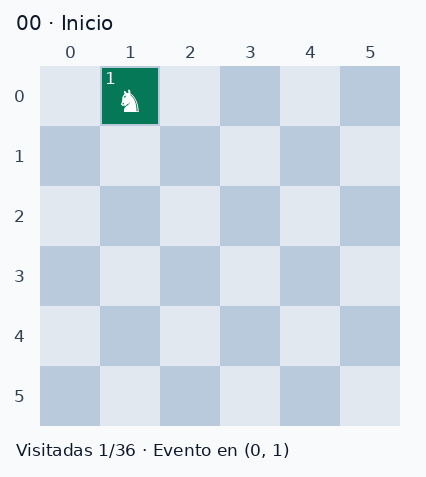

In [23]:
orden_caso = rotate(DESPLAZAMIENTOS, CASO["rotacion"])
estado_caso, camino_caso, traza_caso, expansiones_caso = resolver(
    CASO["n"], CASO["inicio"], orden=orden_caso, presupuesto=PRESUPUESTO)
print("Orden rotado:", orden_caso)
print(f"Ejecución completa: {estado_caso}, {expansiones_caso} expansiones, {len(traza_caso)} eventos")

r = next(k for k, e in enumerate(traza_caso) if e[0] == "retroceso")
caminos_caso = replay(traza_caso[:r + 6])
libre = traza_caso[r][1:]
queda = caminos_caso[r][-1]
pendientes = saltos_legales(CASO["n"], queda, set(caminos_caso[r]), orden_caso)
print(f"Primer retroceso: evento {r}. Se libera {libre}; el caballo queda en {queda}.")
print(f"Destinos libres desde {queda} en el orden rotado (sin contar {libre}, que ya se probó): "
      f"{[d for d in pendientes if d != libre]}")
print("Eventos siguientes:", traza_caso[r + 1:r + 6])

prefijo = traza_caso[:r + 6]
gif_caso = gif_traza(CASO["n"], prefijo)
display(NotebookImage(data=gif_caso, format="gif"))

**Qué pasa en la rama fallida.**

- **Hasta el evento 25** el caballo avanza sin problemas por 26 casillas y llega a `(5, 5)`, la esquina de abajo a la derecha.
- **En `(5, 5)` no tiene saltos libres:** `(3, 4)` y `(4, 3)` ya están en el camino. En el **evento 26** retrocede: se libera `(5, 5)` (la del aspa) y el caballo queda en `(4, 3)`.
- **El marco de `(4, 3)` sigue con su ciclo.** En el orden rotado, después de `(5, 5)` su siguiente destino libre es `(2, 2)`, y ese es el avance del evento 27.
- **El evento 31 es otro retroceso**, ahora desde `(3, 0)`. Esa segunda rama tampoco funciona, y la búsqueda seguirá deshaciendo hasta encontrar una alternativa. El recorrido completo aparece recién tras 31 042 expansiones.

Los fotogramas de abajo son el 25 (antes) y el 26 (el retroceso).

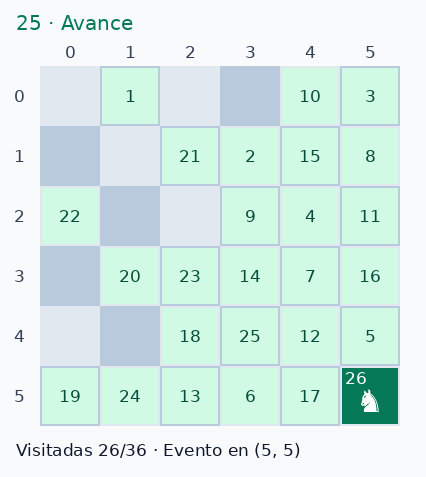

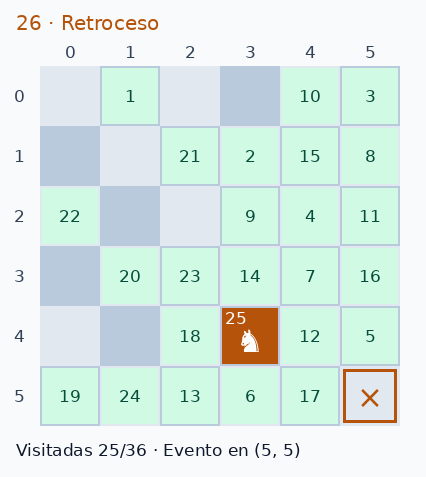

In [24]:
for k in (r - 1, r):
    display(NotebookImage(data=ver_fotograma(CASO["n"], traza_caso, k), format="png"))

In [25]:
from pathlib import Path

Path("figuras").mkdir(exist_ok=True)
Path("figuras/recorrido_6x6_prefijo.gif").write_bytes(gif_caso)
print("GIF guardado en figuras/recorrido_6x6_prefijo.gif")

GIF guardado en figuras/recorrido_6x6_prefijo.gif


**Un cambio de parámetro, con la predicción escrita antes de ejecutar.**

*Cambio A: presupuesto de 50 000 a 20 000*, mismo caso y estrategia fija. Sabemos que con fijo hacen falta 31 042 expansiones, así que predecimos: estado **límite**, exactamente **20 000** expansiones (el corte ocurre justo al llegar al presupuesto), **19 999** retrocesos (se desenrolla todo hasta la raíz), camino `None` y último evento `("límite", 0, 1)`, porque el camino queda solo con el inicio.

*Cambio B: intercambiar los saltos 2 y 3 del orden rotado*, `(1, 2)` y `(2, 1)`. Desde `(0, 1)`, los dos primeros saltos del orden rotado, `(-2, 1)` y `(-1, 2)`, se salen por arriba. Antes del cambio el primer destino era `(0 + 1, 1 + 2) = (1, 3)`; después del cambio el primero que cabe es `(2, 1)`, que lleva a `(2, 2)`. Predecimos que el primer avance será `("avance", 2, 2)`. No predecimos el estado final: el resto del árbol cambia y no sabemos calcularlo a mano.

In [26]:
estado, camino, traza, expansiones = resolver(CASO["n"], CASO["inicio"], orden=orden_caso, presupuesto=20_000)
print("A:", estado, camino, expansiones, "expansiones,",
      sum(e[0] == "retroceso" for e in traza), "retrocesos, último evento", traza[-1])

orden_b = list(orden_caso)
orden_b[2], orden_b[3] = orden_b[3], orden_b[2]
estado, _, traza, expansiones = resolver(CASO["n"], CASO["inicio"], orden=tuple(orden_b), presupuesto=PRESUPUESTO)
print("B: primer avance antes:", traza_caso[1], "| después:", traza[1], f"| estado: {estado}, {expansiones} expansiones")

A: límite None 20000 expansiones, 19999 retrocesos, último evento ('límite', 0, 1)
B: primer avance antes: ('avance', 1, 3) | después: ('avance', 2, 2) | estado: éxito, 30790 expansiones


Las dos predicciones se cumplieron. En el cambio B, además, la búsqueda terminó con éxito y con un poco menos de trabajo (30 790 contra 31 042 expansiones). Eso no lo predijimos.

### SOLUCIÓN · sección 4

**Traza manual anotada.** Este es el fragmento que reconstruimos a mano: los eventos 20 a 27 de la traza 5x5 desde `(0, 0)`, que es la del docente y también la nuestra. La versión dibujada, con la pila de llamadas, está en `ejercicios_a_mano/`.

| Evento | Tipo | Casilla | Visitadas | Qué pasa |
|---:|---|---|---:|---|
| 20 | avance | (2, 2) | 21 | El marco de `(3, 0)` prueba su primer destino. |
| 21 | avance | (0, 3) | 22 | Desde `(2, 2)` el único salto libre es `(0, 3)`. |
| 22 | avance | (1, 1) | 23 | Desde `(0, 3)` el único salto libre es `(1, 1)`. |
| 23 | retroceso | (1, 1) | 22 | `(1, 1)` no tiene saltos libres: su llamada fracasa y se libera. |
| 24 | retroceso | (0, 3) | 21 | A `(0, 3)` no le quedan alternativas: también fracasa. |
| 25 | retroceso | (2, 2) | 20 | Lo mismo con `(2, 2)`. El caballo vuelve a `(3, 0)`. |
| 26 | avance | (1, 1) | 21 | El marco de `(3, 0)` prueba su segundo destino. `(1, 1)` estaba libre otra vez. |
| 27 | avance | (0, 3) | 22 | Ahora desde `(1, 1)`. Es la misma casilla de antes, pero otro camino. |

**Una decisión de implementación para cada integrante.**

- *Santiago: dónde se revisa el presupuesto.* Se revisa antes de cada avance y no al entrar a la llamada. Así una llamada ya contada puede reconocer el caso base aunque haya gastado la última expansión (como en 1x1 con presupuesto 1), y un avance que no se puede procesar no aparece en la traza. Con presupuesto 2 en 5x5 la traza es `inicio, avance, retroceso, límite`, que es lo que pide `probar_resolver`.
- *Juan Manuel: solo dos funciones tocan el estado.* `advance` agrega a `camino`, a `visitadas` y a la traza; `retreat` deshace las tres cosas. Como nadie más modifica el camino, la traza no puede quedar desfasada de la búsqueda, y el invariante se comprueba en un solo lugar.

**Para anticipar efectos en la sustentación.** La tabla de abajo da, para cada rotación de `DESPLAZAMIENTOS`, el primer destino desde nuestro inicio y desde `(0, 0)` en 5x5. La regla para hacerlo a mano: recorrer el orden y quedarse con el primer salto que cae dentro del tablero. Con un presupuesto muy pequeño el resultado también se predice: con presupuesto 1 la traza es `inicio, límite`, y con presupuesto `p` menor que lo que necesita la búsqueda el estado es límite con `p` expansiones y `p - 1` retrocesos.

In [27]:
filas = []
for k in range(8):
    orden = rotate(DESPLAZAMIENTOS, k)
    filas.append({"Rotación": k, "Primer salto del orden": orden[0],
                  f"Primer destino desde {CASO['inicio']} ({CASO['n']}x{CASO['n']})":
                      saltos_legales(CASO["n"], CASO["inicio"], {CASO["inicio"]}, orden)[0],
                  "Primer destino desde (0, 0) (5x5)": saltos_legales(5, (0, 0), {(0, 0)}, orden)[0]})
display(pd.DataFrame(filas))

,Rotación,Primer salto del orden,"Primer destino desde (0, 1) (6x6)","Primer destino desde (0, 0) (5x5)"
0,0,"(-1, 2)","(1, 3)","(1, 2)"
1,1,"(1, 2)","(1, 3)","(1, 2)"
2,2,"(2, 1)","(2, 2)","(2, 1)"
3,3,"(2, -1)","(2, 0)","(1, 2)"
4,4,"(1, -2)","(1, 3)","(1, 2)"
5,5,"(-1, -2)","(1, 3)","(1, 2)"
6,6,"(-2, -1)","(1, 3)","(1, 2)"
7,7,"(-2, 1)","(1, 3)","(1, 2)"


**Prueba adicional.** `probar_extra` comprueba tres cosas que las pruebas del enunciado no miran:

1. **Existencia contra el oráculo.** En 5x5, desde cada casilla donde el oráculo encontró un recorrido (`EXISTE_5X5`, Reto 3), `resolver` tiene éxito con las dos estrategias y el recorrido es válido. Las casillas sin recorrido ya se compararon arriba; no repetimos esas 12 búsquedas completas.
2. **Conteo exacto en los fracasos.** En 3x3 y 4x4, desde cada casilla, `resolver` fracasa y sus expansiones son exactamente los nodos del árbol que cuenta el oráculo.
3. **Traza coherente.** En todas esas corridas cada retroceso retira la última casilla del camino (lo comprueba `replay`).

In [28]:
def probar_extra(resolver=resolver):
    for (f, c), existe in EXISTE_5X5.items():
        if not existe:
            continue
        for estrategia in ("fijo", "warnsdorff"):
            estado, camino, traza, _ = resolver(5, (f, c), estrategia=estrategia, presupuesto=10**6)
            assert estado == "éxito" and recorrido_valido(5, (f, c), camino), (f, c, estrategia, estado)
            replay(traza)
    for n in (3, 4):
        for f in range(n):
            for c in range(n):
                _, nodos = oracle(n, (f, c), DESPLAZAMIENTOS)
                estado, _, traza, expansiones = resolver(n, (f, c), presupuesto=10**6)
                assert estado == "fracaso" and expansiones == nodos, (n, f, c, expansiones, nodos)
                replay(traza)


probar_extra()
print("probar_extra: pasa")

probar_extra: pasa


**Qué error habría detectado.** Lo comprobamos rompiendo `resolver` a propósito, con tres errores creíbles, y corriendo las pruebas del enunciado y la nuestra sobre cada versión rota:

- **Warnsdorff sin retroceso** (solo prueba el primer candidato). El enunciado lo advierte en el Reto 3, pero `probar_resolver` solo usa 5x5 desde `(0, 0)`, donde Warnsdorff acierta a la primera.
- **El retroceso registra la casilla equivocada** (a la que vuelve el caballo y no la que se libera). Es fácil confundirlas al leer la descripción de la animación. `probar_resolver` solo mira los tipos de evento, no las coordenadas.
- **No quitar la casilla de `visitadas` al retroceder.** Este sí lo detectan las pruebas del enunciado; lo dejamos para comparar.

In [29]:
def broken_versions():
    fuente = getsource(resolver)
    cambios = {
        "Warnsdorff sin retroceso": (
            "        for destino in candidates():\n",
            "        for destino in (candidates()[:1] if estrategia == \"warnsdorff\" else candidates()):\n"),
        "Retroceso con la casilla equivocada": (
            'traza.append(("retroceso", *square))', 'traza.append(("retroceso", *camino[-1]))'),
        "No liberar la casilla en visitadas": ("        visitadas.discard(square)\n", ""),
    }
    for nombre, (viejo, nuevo) in cambios.items():
        assert viejo in fuente, nombre
        espacio = {**globals()}
        exec(fuente.replace(viejo, nuevo).replace("        assert len(visitadas) == len(camino)\n", ""), espacio)
        yield nombre, espacio["resolver"]


def outcome(prueba, version):
    global resolver
    original = resolver
    resolver = version
    try:
        prueba()
        return "pasa"
    except AssertionError:
        return "FALLA"
    finally:
        resolver = original


filas = []
for nombre, version in broken_versions():
    filas.append({"Versión rota": nombre,
                  "probar_resolver (enunciado)": outcome(probar_resolver, version),
                  "probar_extra (nuestra)": outcome(lambda: probar_extra(version), version)})
display(pd.DataFrame(filas))
print("Con el resolver correcto:", outcome(probar_resolver, resolver), "/", outcome(probar_extra, resolver))

,Versión rota,probar_resolver (enunciado),probar_extra (nuestra)
0,Warnsdorff sin retroceso,pasa,FALLA
1,Retroceso con la casilla equivocada,pasa,FALLA
2,No liberar la casilla en visitadas,FALLA,FALLA


Con el resolver correcto: pasa / pasa


Los dos primeros errores pasan las pruebas del enunciado y nuestra prueba los detecta. El primero falla porque Warnsdorff sin retroceso se queda sin salida desde casillas como `(1, 1)`, donde el recorrido sí existe. El segundo falla porque `replay` encuentra un retroceso que no corresponde a la última casilla del camino. En el cuaderno ese error rompería también la animación (`fotogramas` lanza "Retroceso incoherente"), pero solo si alguien la genera con esa traza.

**Lista de entrega.**

| Pide el enunciado | Dónde está |
|---|---|
| Cuaderno ejecutado | Este archivo, con todas las salidas |
| Traza manual anotada | Tabla de arriba (eventos 20 a 27) y `ejercicios_a_mano/` |
| Código propio | `saltos_legales` y `resolver` (Retos 1 y 2), oráculo (Reto 3) |
| Tabla comparativa | Reto 3, punto 4 |
| Fotograma o GIF comentado | Reto 4: GIF de nuestro caso, fotogramas 25 y 26 y su explicación |
| Prueba adicional y qué comprueba | `probar_extra` y la tabla de versiones rotas, aquí arriba |

| Criterio | Dónde lo cubrimos |
|---|---|
| Saltos legales, caso base y restauración del estado (35 %) | Sección 1, Retos 1 y 2 (casos a mano, invariante en una rama fallida) |
| Pruebas y las tres salidas de búsqueda (20 %) | Retos 2 y 3: éxito (5x5), fracaso (3x3, 1x1 cerrado), límite (5x5 cerrado, cambio A) |
| Comparación reproducible y explicación del cierre (20 %) | Reto 3, puntos 2 a 4 |
| Animación propia y sustentación (25 %) | Reto 4, traza manual, decisiones y tabla para anticipar efectos |

**Referencias.**

1. Enunciado del taller, *Backtracking y el recorrido del caballo*, IS784.
2. H. C. von Warnsdorff (1823). *Des Rösselsprunges einfachste und allgemeinste Lösung*. Schmalkalden. Origen de la regla de Warnsdorff.
3. A. J. Schwenk (1991). Which rectangular chessboards have a knight's tour? *Mathematics Magazine*, 64(5), 325-332. Cuándo existe recorrido cerrado; incluye el argumento de colores para tableros impares.
4. Stuart Russell y Peter Norvig. *Artificial Intelligence: A Modern Approach*, 4.ª edición, capítulo 6 (búsqueda con retroceso).